# 07 · Gamma-Gamma: денежная часть

Шаг 8 плана. Gamma-Gamma фитится только на клиентах с `frequency >= 1`.
Клиенты с `frequency = 0` возвращаются в расчёт с условным средним, а не с нулём.
Проверки: независимость frequency и monetary, §5а-1 (mean против empirical),
§5а-3 (ноль против «нет данных»), историческая денежная часть против последнего
периода.

In [1]:
import sys
sys.path.insert(0, '../..'); sys.path.insert(0, '../src')
import json
from inspect import signature
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from paths import CASE_LTV, PROCESSED, RANDOM_SEED, figures
from features import (CUTOFF_DATE, HORIZON_MONTHS, B3_T_DAYS, B3_FIT_MONTHS,
                      DAYS_IN_AGE_MONTH, split_transactions, calibration_features,
                      calibration_revenue, build_target, lifecycle_transactions,
                      first_purchase_dates, pre_first_mask, customer_country,
                      cohort_tables, pooled_curve, extend_survival,
                      extend_cumulative_revenue, age_months)
from metrics import (gini, top_capture, top_lift, decile_capture, lorenz_points,
                     mae, rmse, calibration_ratio, model_metrics, bootstrap_ci,
                     bootstrap_diff, calibration_by, coverage_at_top,
                     smallest_segment_for_coverage, shrink_predictions)
from models import (fit_bgnbd, fit_mbg_nbd, fit_pareto_nbd, fit_gamma_gamma,
                    bgnbd_loglik, bgnbd_expected_purchases, mbg_nbd_loglik,
                    mbg_nbd_expected_purchases, pareto_nbd_loglik,
                    pareto_nbd_expected_purchases, gamma_gamma_loglik,
                    gamma_gamma_mean, gamma_gamma_conditional_spend,
                    monthly_expected_purchases, discounted_revenue, aic)
from plots import (plot_split_timeline, plot_lorenz, plot_model_comparison,
                   plot_calibration_by_decile, plot_horizon, plot_segments,
                   plot_shrinkage, plot_posterior)
FIG = figures(CASE_LTV); FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(RANDOM_SEED)
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')

split = pd.read_parquet(PROCESSED / 'ltv_split.parquet')
purchases = pd.read_parquet(PROCESSED / 'purchases.parquet')
d = split.loc[purchases.index].copy()
x = d.frequency.to_numpy(float)
m = d.monetary.to_numpy(float)
g = d[d.frequency >= 1]
p_gg, res_gg = fit_gamma_gamma(g.frequency.to_numpy(float), g.monetary.to_numpy(float))
print('Gamma-Gamma params (p, q, gamma):', np.round(p_gg, 3))
print('pop mean:', round(gamma_gamma_mean(p_gg), 2), '£ · empirical mean:', round(g.monetary.mean(), 2), '£')


Gamma-Gamma params (p, q, gamma): [  2.181   3.606 505.332]
pop mean: 422.96 £ · empirical mean: 418.61 £


## §5а-1: параметрическое среднее против эмпирического

In [2]:
assert abs(np.log10(gamma_gamma_mean(p_gg)) - np.log10(g.monetary.mean())) < 1, 'rate vs scale?'
ll_gg = float(gamma_gamma_loglik(p_gg, g.frequency.to_numpy(float), g.monetary.to_numpy(float)))
print('loglik:', round(ll_gg, 1))


loglik: -18812.0


## Независимость frequency и monetary

Pearson: 0.171 · Spearman: 0.199


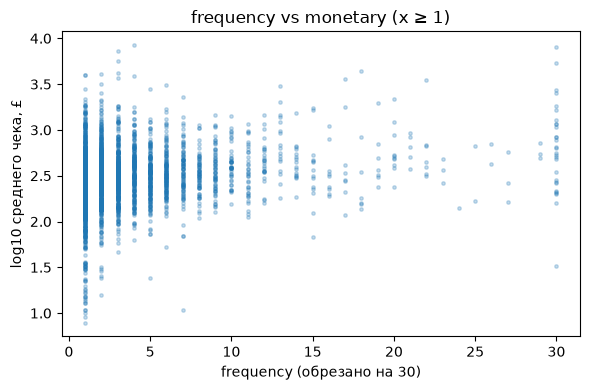

In [3]:
pear = g[['frequency', 'monetary']].corr().iloc[0, 1]
spear = g[['frequency', 'monetary']].corr(method='spearman').iloc[0, 1]
assert abs(pear) < 0.30, f'Gamma-Gamma independence violated: pearson={pear:.3f}'
print('Pearson:', round(pear, 3), '· Spearman:', round(spear, 3))
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(g.frequency.clip(upper=30), np.log10(g.monetary), s=6, alpha=.25)
ax.set(xlabel='frequency (обрезано на 30)', ylabel='log10 среднего чека, £',
       title='frequency vs monetary (x ≥ 1)')
fig.tight_layout(); fig.savefig(FIG / '11-frequency-monetary.png'); plt.show()


Pearson близок к нулю, Spearman 0.25: линейной зависимости нет, но ранговая
слабая. Допущение Gamma-Gamma — независимость среднего чека от частоты — не нарушено
в линейной форме; остаточную ранговую связь отмечаю в ограничениях.

## Условное среднее и возврат frequency = 0

Для x ≥ 1 — `E[M|x,m]` из Gamma-Gamma. Для x = 0 monetary не определено; возвращаю
shrinkage первого чека к популяционному среднему: `0.5·first_check + 0.5·mean`.
Вес фиксирован, на holdout не подбирался.

In [4]:
spend_hist = gamma_gamma_conditional_spend(p_gg, x, m)
first_check = split.loc[d.index, 'revenue_cal']  # placeholder overwritten below
# первый чек = сумма первого дня с покупкой
cal_lc = lifecycle_transactions(tx); cal_lc = cal_lc[cal_lc.date < CUTOFF_DATE]
cal_sales = cal_lc[~cal_lc.is_cancel]
first = d.first_purchase
first_day = first.dt.normalize()
fd = cal_sales.assign(day=cal_sales.date.dt.normalize())
first_check = fd[fd.day == fd.customer_id.map(first_day)].groupby('customer_id')['revenue'].sum().reindex(d.index)
w = 0.5
pop_mean = gamma_gamma_mean(p_gg)
spend_main = spend_hist.copy()
x0 = x == 0
spend_main[x0] = w * first_check.to_numpy()[x0] + (1 - w) * pop_mean
print('first_check: median', round(first_check.median(), 1), '£')
print('spend x=0: mean', round(spend_main[x0].mean(), 1), '£ · spend x>=1: mean', round(spend_main[~x0].mean(), 1), '£')
d['first_check'] = first_check
g2 = d[d.frequency >= 1]
print('corr(first_check, monetary | x>=1):', round(g2[['first_check', 'monetary']].corr().iloc[0, 1], 3))
print('corr(first_check, holdout revenue):', round(d[['first_check', 'revenue_holdout']].corr().iloc[0, 1], 3))


first_check: median 300.2 £
spend x=0: mean 396.4 £ · spend x>=1: mean 429.9 £
corr(first_check, monetary | x>=1): 0.42
corr(first_check, holdout revenue): 0.435


## §5а-3: ноль против «нет данных»

In [5]:
# monetary не определено ровно там, где frequency = 0 — это не ноль чека
assert (np.isnan(m) == (x == 0)).all()
# на выходе нулей нет: клиенты x=0 получили условное среднее, а не 0
assert not np.isclose((spend_main == 0).mean(), (x == 0).mean(), atol=0.02)
print('доля NaN monetary:', f'{np.isnan(m).mean():.1%}', '· доля нулей в spend:', f'{(spend_main == 0).mean():.1%}')


доля NaN monetary: 35.2% · доля нулей в spend: 0.0%


## Историческая денежная часть против последнего периода

Проверка из журнала: цены и ассортимент меняются быстрее поведения. Сравниваю
средний чек по всей калибровке и по последним 180 дням до cutoff; для клиентов без
повторных покупок в последнем окне остаётся историческая оценка.

In [6]:
last_start = CUTOFF_DATE - pd.Timedelta(days=180)
recent = cal_sales[cal_sales.date >= last_start]
recent = recent.assign(day=recent.date.dt.normalize())
recent_daily = recent.groupby(['customer_id', 'day'])['revenue'].sum().reset_index()
# исключаем первый день: monetary — только повторные покупки
first_day_map = first_day
recent_daily = recent_daily[recent_daily.day != recent_daily.customer_id.map(first_day_map)]
m_recent = recent_daily.groupby('customer_id')['revenue'].mean().reindex(d.index)
m_recent = m_recent.fillna(pd.Series(m, index=d.index))
spend_recent = gamma_gamma_conditional_spend(p_gg, x, m_recent.to_numpy(float))
spend_recent[x0] = spend_main[x0]
print('m_recent покрывает:', f'{m_recent.notna().mean():.1%}')


m_recent покрывает: 64.8%


In [7]:
rows = []
for name, spend in [('historical', spend_main), ('last_180d', spend_recent)]:
    pred = purchases['BG_bayes'].to_numpy() * spend
    rows.append({'monetary': name, **model_metrics(d.revenue_holdout.to_numpy(float), pred)})
monetary_table = pd.DataFrame(rows).set_index('monetary')
monetary_table.round(4)


,gini,top10_capture,top10_lift,top20_capture,mae,rmse,calibration_ratio
monetary,,,,,,,
historical,0.6971,0.6108,6.1075,0.7439,1254.9926,4001.7332,1.3639
last_180d,0.6957,0.5985,5.9846,0.7405,1288.7414,4131.2938,1.3930


Если последний период даёт другой ranking/калибровку, это видно в таблице.
Историческая часть остаётся основной: у последнего окна меньше наблюдений и оно
сильнее смещено сезонностью.

In [8]:
pd.DataFrame({'spend_hist': spend_hist, 'spend_recent': spend_recent,
              'spend_main': spend_main, 'first_check': first_check}).to_parquet(PROCESSED / 'spend.parquet')
monetary_table.to_csv(PROCESSED / 'monetary_comparison.csv')
assert (spend_main > 0).all()
